<a href="https://colab.research.google.com/github/aunyarit2005-hash/Comparative-Performance-Analysis-of-Image-Classification-Models-for-Malaria-Infected-Red-Blood-Cells/blob/main/Origin_model_ResNet18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 ResNet18 Architecture

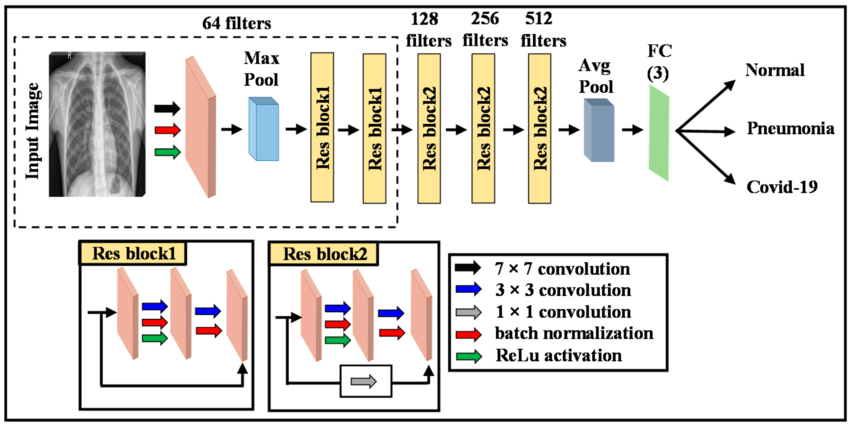

##🔌เเตก zip


In [ ]:
!unzip /content/Segment_Malariae-20260219T013031Z-1-001.zip -d /content/

Archive:  /content/Segment_Malariae-20260219T013031Z-1-001.zip
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225339.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225237.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225403.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225242.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225307.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225318.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225139.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225421.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225300.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 225141.png  
  inflating: /content/Segment_Malariae/malaria/val/Screenshot 2026-02-12 2251

# 📁 กำหนดเส้นทาง (Path) สำหรับข้อมูลภาพ Normal และ Malaria
รายละเอียดในโค้ด:
📂 ชุดข้อมูลฝึกสอน (Train): สำหรับให้โมเดลเรียนรู้ลักษณะของเซลล์

🧪 ชุดข้อมูลตรวจสอบ (Validation): สำหรับเช็กความแม่นยำระหว่างเทรน

🔍 ชุดข้อมูลทดสอบ (Test): สำหรับวัดผลหลังเทรนเสร็จว่าแยกแยะได้จริงไหม

In [ ]:
import os
file_path = '/content/Segment_Malariae'
# normal_train and malaria_train
normal_train = os.path.join(file_path, 'normal', 'train')
malaria_train = os.path.join(file_path, 'malaria', 'train')

# normal_Validation and malaria_Validation
normal_val = os.path.join(file_path, 'normal', 'val')
malaria_val = os.path.join(file_path, 'malaria', 'val')

# normal_test and malaria_test
normal_test = os.path.join(file_path, 'normal', 'test')
malaria_test = os.path.join(file_path, 'malaria', 'test')

# 🛠️ ฟังก์ชันสำหรับดึง Path ของไฟล์ภาพและกำหนด Label (ป้ายกำกับ)
🔍 การค้นหาไฟล์: ไล่ดูไฟล์ในโฟลเดอร์ที่กำหนดไว้ (Directory)

🖼️ กรองเฉพาะรูปภาพ: เลือกเอาเฉพาะไฟล์นามสกุล .jpg, .jpeg, .png, .gif เท่านั้น

🏷️ ติดป้ายกำกับ: จับคู่รูปภาพกับประเภท (เช่น Normal หรือ Malaria) เพื่อส่งค่ากลับไปเป็น List

In [ ]:
import os
import pandas as pd

# Define a function to get file paths and labels from a directory
def get_filepaths_and_labels(directory, label):
    filepaths = [] # Corrected: initialize as empty list
    labels = []    # Corrected: initialize as empty list
    # Ensure the directory exists before listing its contents
    if os.path.exists(directory):
        for filename in os.listdir(directory):
            # Check for common image file extensions
            if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.gif')):
                filepaths.append(os.path.join(directory, filename))
                labels.append(label)
    else:
        print(f"Warning: Directory not found: {directory}")
    return filepaths, labels

# สร้าง DataFrame สำหรับชุดข้อมูลฝึกสอน (Training Set)
🔗 รวมข้อมูล: เอาลิสต์รายชื่อไฟล์และป้ายกำกับ (Labels) จากทั้งฝั่ง Normal และ Malaria มารวมเข้าด้วยกัน

📝 จัดรูปแบบตาราง: นำข้อมูลทั้งหมดมาสร้างเป็น pd.DataFrame โดยแบ่งเป็นคอลัมน์ filepath (ที่อยู่ไฟล์) และ label (ประเภทของภาพ)

📈 ตรวจสอบจำนวน: แสดงยอดรวมของรูปภาพทั้งหมดที่มีอยู่ในชุด Train เพื่อเช็กความเรียบร้อย

In [ ]:
# --- Create Training DataFrame ---
# Get file paths and labels for normal training data
normal_train_filepaths, normal_train_labels = get_filepaths_and_labels(normal_train, 'normal')

# Get file paths and labels for malaria training data
malaria_train_filepaths, malaria_train_labels = get_filepaths_and_labels(malaria_train, 'malaria')

# Combine file paths and labels for the entire training set
train_filepaths = normal_train_filepaths + malaria_train_filepaths
train_labels = normal_train_labels + malaria_train_labels

# Create the training DataFrame
train_df = pd.DataFrame({'filepath': train_filepaths, 'label': train_labels})

print("✅ สร้าง DataFrame สำหรับ Training เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Train DataFrame: {len(train_df)}")

✅ สร้าง DataFrame สำหรับ Training เสร็จแล้ว!
จำนวนรูปภาพใน Train DataFrame: 1600


#🔍แสดงตัวอย่างข้อมูลใน Traning set ใน DataFrame

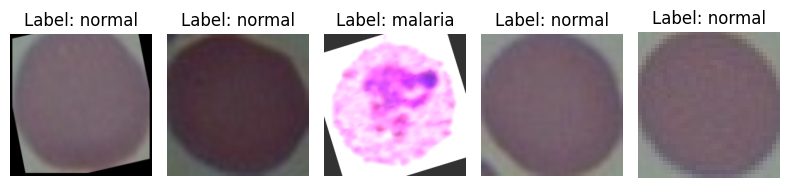

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = train_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🧪 สร้าง DataFrame สำหรับชุดตรวจสอบ (Validation Set) และการสลับลำดับข้อมูล
🔄 เตรียมชุด Validation: ทำเหมือนกับชุด Train เลย คือดึง Path และ Label ของฝั่ง Normal และ Malaria มารวมเป็น val_df

🔀 สลับข้อมูล (Shuffle): ใช้คำสั่ง .sample(frac=1) เพื่อสลับตำแหน่งแถวในตารางให้มั่วซั่ว (Random) ป้องกันไม่ให้โมเดลเรียนรู้แบบท่องจำลำดับไฟล์

In [ ]:
normal_val_filepaths, normal_val_labels = get_filepaths_and_labels(normal_val, 'normal')

# Get file paths and labels for malaria validation data
malaria_val_filepaths, malaria_val_labels = get_filepaths_and_labels(malaria_val, 'malaria')

# Combine file paths and labels for the entire validation set
val_filepaths = normal_val_filepaths + malaria_val_filepaths
val_labels = normal_val_labels + malaria_val_labels

# Create the validation DataFrame
val_df = pd.DataFrame({'filepath': val_filepaths, 'label': val_labels})

# Shuffle the DataFrames to ensure randomness during training
train_df = train_df.sample(frac=1).reset_index(drop=True)
val_df = val_df.sample(frac=1).reset_index(drop=True)

print("✅ สร้าง DataFrame สำหรับ Validation เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Validation DataFrame: {len(val_df)}")

✅ สร้าง DataFrame สำหรับ Validation เสร็จแล้ว!
จำนวนรูปภาพใน Validation DataFrame: 200


# 🔍แสดงตัวอย่างข้อมูลใน Validation ใน DataFrame

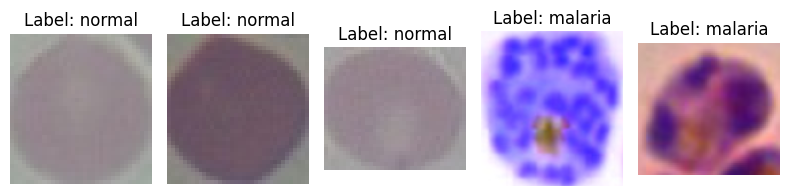

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = val_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🔍สร้าง DataFrame สำหรับชุดข้อมูลทดสอบ (Test Set)

In [ ]:
# Get file paths and labels for normal test data
normal_test_filepaths, normal_test_labels = get_filepaths_and_labels(normal_test, 'normal')

# Get file paths and labels for malaria test data using the corrected path
malaria_test_filepaths, malaria_test_labels = get_filepaths_and_labels(malaria_test, 'malaria')

# Combine file paths and labels for the entire test set
test_filepaths = normal_test_filepaths + malaria_test_filepaths
test_labels = normal_test_labels + malaria_test_labels

# Create the test DataFrame
test_df = pd.DataFrame({'filepath': test_filepaths, 'label': test_labels})

# Shuffle the DataFrame to ensure randomness
test_df = test_df.sample(frac=1).reset_index(drop=True)

print(f"✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว!")
print(f"จำนวนรูปภาพใน Test DataFrame: {len(test_df)}")

✅ สร้าง DataFrame สำหรับ Test เสร็จแล้ว!
จำนวนรูปภาพใน Test DataFrame: 200


# 🔍แสดงตัวอย่างข้อมูลใน Test set ใน DataFrame

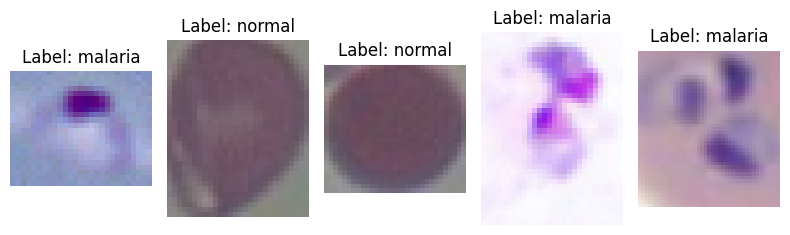

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images = test_df.sample(n=5)

plt.figure(figsize=(8, 8))
for i, row in enumerate(sample_images.itertuples()):
    filepath = row.filepath
    label = row.label

    # โหลดรูปภาพ
    image = Image.open(filepath)

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Label: {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 🧠 สร้างและตั้งค่าโมเดล Deep Learning (ResNet18)

In [ ]:

# --- 0. ติดตั้งแพ็กเกจที่จำเป็น ---
!pip install image-classifiers

import tensorflow as tf
from classification_models.tfkeras import Classifiers
from tensorflow.keras.layers import Dense, Dropout, Input, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# --- 1. โหลดโมเดล ResNet18 ---
# ดึงโครงสร้าง ResNet18 ออกมา
ResNet18, preprocess_input = Classifiers.get('resnet18')

# กำหนด Input layer สำหรับโมเดลทั้งหมด
input_tensor = Input(shape=(224, 224, 3))

# สร้าง Base Model
base_model = ResNet18(
    input_shape=(224, 224, 3), # input_shape ยังคงต้องระบุใน base_model
    weights='imagenet',   # ใช้ Weight ที่เทรนจาก ImageNet
    include_top=False,    # ไม่เอาส่วนหัวเดิม
    pooling=None          # เปลี่ยนเป็น None เพราะเราจะเพิ่ม GlobalAveragePooling2D ด้วยตัวเอง
)

# --- 2. ปิดสมองส่วนต้น (Freeze Base) ---
base_model.trainable = False

# --- 3. ต่อหัวใหม่ให้เหมาะกับงานเรา ---
x = base_model(input_tensor) # ส่ง input_tensor เข้า base_model โดยตรง
x = GlobalAveragePooling2D()(x) # เพิ่ม GlobalAveragePooling2D เพื่อลดขนาดมิติเชิงพื้นที่
x = Dropout(0.2)(x)
predictions = Dense(2, activation='softmax')(x) # 2 คือจำนวนคลาส (เช่น Normal, Malaria)

# --- 4. รวมร่าง ---
model = Model(inputs=input_tensor, outputs=predictions) # ใช้ input_tensor ที่เราสร้างขึ้น

# --- 5. ตั้งค่ากระบวนการเรียนรู้ (Compile) ---
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ สร้างโมเดล ResNet18 เสร็จแล้ว! พร้อมใช้งาน")
model.summary()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 4.5 MB/s eta 0:00:00
44920640/44920640 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
✅ สร้างโมเดล ResNet18 เสร็จแล้ว! พร้อมใช้งาน


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 7, 7, 512)      │    11,186,889 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,187,915 (42.68 MB)

 Trainable params: 1,026 (4.01 KB)

 Non-trainable params: 11,186,889 (42.67 MB)

#🖼️ เตรียม Data Generator และการตั้งค่า Early Stopping

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

# --- 1. เตรียมดูดรูป (Data Generator) ---
# Data Generator สำหรับ Training
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input, # แปลงค่าสีให้เหมาะกับ ResNet18
    shear_range=0.2,             # Shear transformations
    zoom_range=0.2,              # Zoom transformations
    horizontal_flip=True         # Horizontal flip
)

# Data Generator สำหรับ Validation
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # แปลงค่าสีให้เหมาะกับ ResNet18
)

# --- 2. สร้างตัวส่งข้อมูล (Generator) จาก DataFrame ---

# Training Generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,      # ใช้ DataFrame ที่เราสร้างขึ้นมา
    x_col='filepath',        # ชื่อคอลัมน์ที่เก็บ path รูปภาพ
    y_col='label',           # ชื่อคอลัมน์ที่เก็บ class label
    target_size=(224, 224),  # บังคับขนาดรูปภาพ
    batch_size=96,
    class_mode='categorical' # เพราะมี 2 คลาส (Normal, Malaria)
)

# Validation Generator
validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,        # ใช้ DataFrame ของ Validation Set
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=96,
    class_mode='categorical'
)

# --- 3. ตั้งค่า Callbacks ---
# Early Stopping เพื่อหยุดการเทรนเมื่อ Validation Loss ไม่ลดลงอีกแล้ว
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]

Found 1600 validated image filenames belonging to 2 classes.
Found 200 validated image filenames belonging to 2 classes.


#🚀 เริ่มขั้นตอนการฝึกสอนโมเดล (Model Training)

In [ ]:
# --- 4. เข้า model.fit ---
EPOCHS = 5 # <---- จำนวนรอบในการ trainmodel ยิ่งเยอะยิ่งนาน เเนะนะ 10 ถึง 20

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator,
    callbacks=callbacks
)

print("🎉 เทรนเสร็จแล้ว!")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 212s 12s/step - accuracy: 0.5100 - loss: 0.8834 - val_accuracy: 0.7700 - val_loss: 0.5062
Epoch 2/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 173s 10s/step - accuracy: 0.5897 - loss: 0.7407 - val_accuracy: 0.8500 - val_loss: 0.4598
Epoch 3/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 201s 10s/step - accuracy: 0.6696 - loss: 0.6290 - val_accuracy: 0.9000 - val_loss: 0.4199
Epoch 4/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 172s 10s/step - accuracy: 0.7254 - loss: 0.5397 - val_accuracy: 0.9200 - val_loss: 0.3857
Epoch 5/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 181s 11s/step - accuracy: 0.7519 - loss: 0.4953 - val_accuracy: 0.9350 - val_loss: 0.3556
🎉 เทรนเสร็จแล้ว!


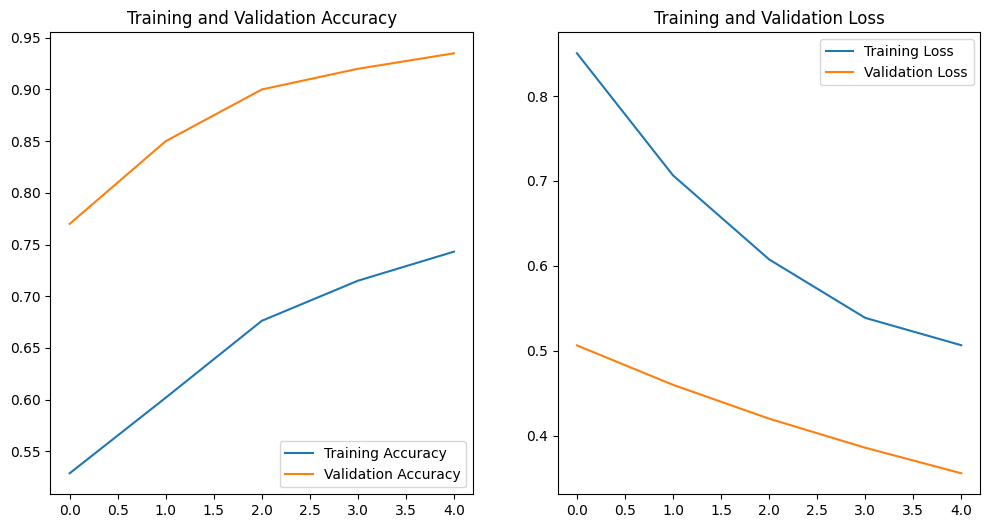

In [ ]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 6))

    # กราฟ Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    # กราฟ Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')

    plt.show()

# เรียกใช้ฟังก์ชันซะ
plot_history(history)

# 📊 นำเข้า Library สำหรับประเมินผลและสร้าง Confusion Matrix ของชุดวัดผล

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

#📝 ตรวจสอบความแม่นยำย้อนหลังบนชุดข้อมูล Validation

In [ ]:
# ให้โมเดลลองทำข้อสอบชุด Validation
print("กำลังตรวจข้อสอบ")
val_loss, val_acc = model.evaluate(validation_generator)

print(f"Loss (ค่าความผิดพลาด): {val_loss:.4f}")
print(f"Accuracy (ความแม่น): {val_acc*100:.2f} %")

กำลังตรวจข้อสอบ
3/3 ━━━━━━━━━━━━━━━━━━━━ 30s 7s/step - accuracy: 0.9402 - loss: 0.3539
Loss (ค่าความผิดพลาด): 0.3556
Accuracy (ความแม่น): 93.50 %


Found 200 validated image filenames belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step


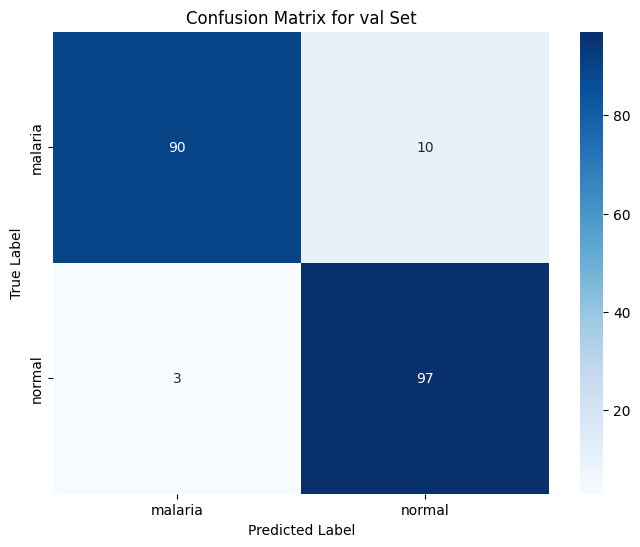

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:
validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df,        # ใช้ DataFrame ของ Validation Set
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


validation_generator.reset()
predictions = model.predict(validation_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())
cm = confusion_matrix(true_classes, predicted_classes)


plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for val Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

# 🏁 เตรียมข้อมูลทดสอบและประเมินประสิทธิภาพของโมเดล (Model Evaluation)

In [ ]:
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # Normalize pixel values for model_ResNet18
)

# Test Generator
test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,       # Use the newly created Test DataFrame
    x_col='filepath',
    y_col='label',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False # Important: do not shuffle test data for consistent evaluation
)

# --- Evaluate the Model ---
print("\nกำลังประเมินผลโมเดลด้วย Test Set...")
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test Loss (ค่าความผิดพลาดบน Test Set): {test_loss:.4f}")
print(f"Test Accuracy (ความแม่นบน Test Set): {test_acc*100:.2f} %")

Found 200 validated image filenames belonging to 2 classes.

กำลังประเมินผลโมเดลด้วย Test Set...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.9144 - loss: 0.3824
Test Loss (ค่าความผิดพลาดบน Test Set): 0.3857
Test Accuracy (ความแม่นบน Test Set): 92.00 %


7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step


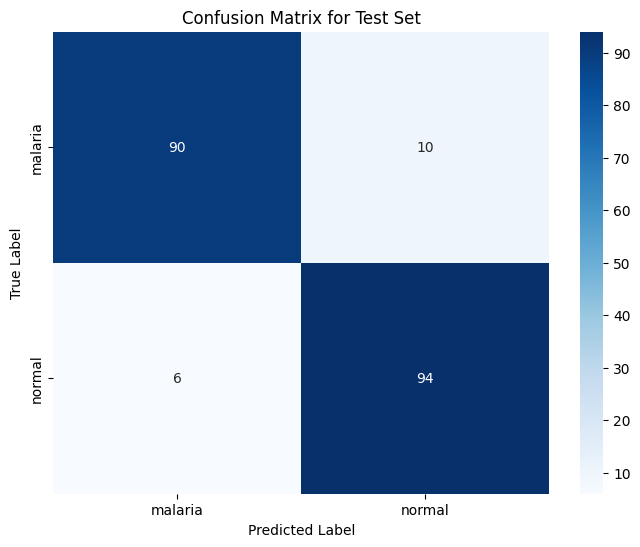

✅ สร้าง Confusion Matrix เสร็จแล้ว!


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Get true labels and predictions ---

# Reset the test_generator to ensure predictions start from the beginning
test_generator.reset()

# Get predictions from the model
predictions = model.predict(test_generator)

# Get predicted class labels (index of the highest probability)
predicted_classes = np.argmax(predictions, axis=1)

# Get true class labels
true_classes = test_generator.classes

# Get class names from the generator
class_names = list(test_generator.class_indices.keys())

# --- 2. Calculate the Confusion Matrix ---
cm = confusion_matrix(true_classes, predicted_classes)

# --- 3. Plot the Confusion Matrix ---
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Test Set')
plt.show()

print("✅ สร้าง Confusion Matrix เสร็จแล้ว!")

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names,
    output_dict=True
)

df = pd.DataFrame(report).transpose()
# df = df.drop(["macro avg", "weighted avg"], errors="ignore")
# ปัดทศนิยมให้ดูสะอาด
df = df.round(3)

# ใส่สีไล่ตามค่า
styled = (
    df.style
    .background_gradient(cmap="YlGnBu")  # โทนฟ้าเขียว
    .format(precision=3)
)

styled

,precision,recall,f1-score,support
malaria,0.938,0.900,0.918,100.000
normal,0.904,0.940,0.922,100.000
accuracy,0.920,0.920,0.920,0.920
macro avg,0.921,0.920,0.920,200.000
weighted avg,0.921,0.920,0.920,200.000


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 680ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


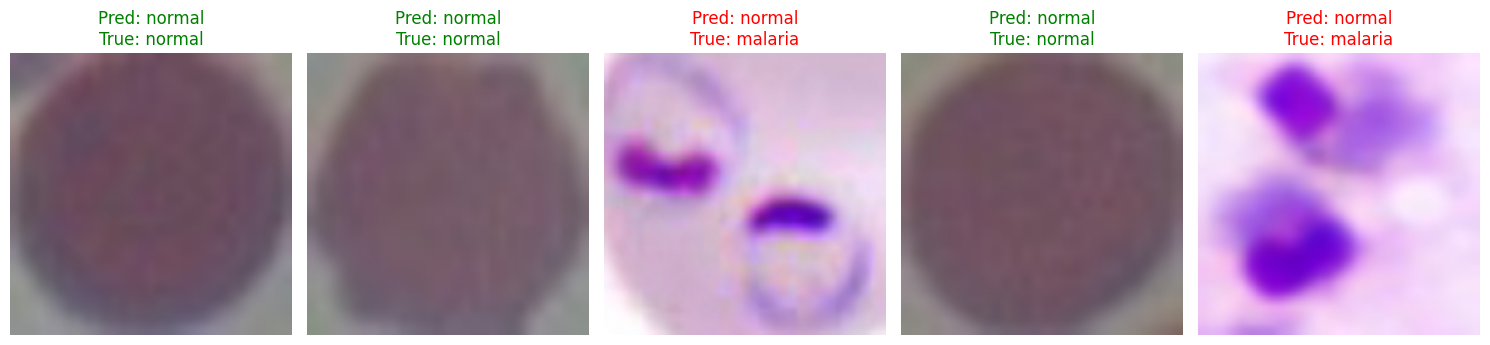

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Data Generator สำหรับการ preprocess รูปภาพก่อนส่งเข้าโมเดล (ไม่ต้อง Augmentation)
test_predict_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input # แปลงค่าสีให้เหมาะกับ MobileNet
)

# สุ่มเลือกรูปภาพ 5 รูปจาก DataFrame
sample_images_df = test_df.sample(n=5) # ใช้ random_state เพื่อให้ผลลัพธ์ซ้ำเดิมได้

plt.figure(figsize=(15, 6))
for i, row in enumerate(sample_images_df.itertuples()):
    filepath = row.filepath
    true_label = row.label

    # โหลดรูปภาพและปรับขนาด
    img = Image.open(filepath).resize((224, 224))
    # === FIX: Convert image to RGB to ensure 3 channels ===
    img = img.convert('RGB')
    # ==================================================
    img_array = np.array(img) # แปลงเป็น numpy array
    img_array = np.expand_dims(img_array, axis=0) # เพิ่มมิติ batch
    img_array = preprocess_input(img_array) # Preprocess ด้วยฟังก์ชันของ MobileNetV2

    # ทำนายผล
    prediction = model.predict(img_array)
    predicted_class_index = np.argmax(prediction, axis=1)[0]
    # ดึงชื่อคลาสจาก class_names ที่สร้างไว้ก่อนหน้านี้
    predicted_label = class_names[predicted_class_index]

    # แสดงรูปภาพ
    plt.subplot(1, 5, i + 1)
    plt.imshow(img) # แสดงรูปภาพก่อน preprocess สำหรับการมองเห็น
    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=('green' if predicted_label == true_label else 'red'))
    plt.axis('off')

plt.tight_layout()
plt.show()
